# Phase 0: Clean the Data

Find duplicates, flag images with burned-in markers and make the train/val/test split.

**Input:** `data/`  
**Output:** `data/manifest.csv`, `data/removed_images.csv`

**Decisions**
- Duplicates with **conflicting labels** are removed, because we can't tell which label is right.
- Duplicates with the **same label** keep one copy only.
- Images with **markers** are only flagged, not changed.

Run this notebook from inside the `ultrasonic_scans/` folder (VS Code does this by default).

## 1. Imports and settings

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from skimage.measure import label, regionprops
from skimage.morphology import white_tophat, disk
from sklearn.model_selection import train_test_split

In [2]:
DATA_DIR = Path('data')                       # folder with benign/, malignant/, normal/
CLASSES = ['normal', 'benign', 'malignant']

MIN_LESION_PIXELS = 50        # mask regions smaller than this are annotation noise
DUPLICATE_THRESHOLD = 3.0     # mean pixel difference (0-255) between 32x32 thumbnails; below this = duplicate
MARKER_PIXEL_THRESHOLD = 30   # number of marker-like pixels needed to flag an image
RANDOM_STATE = 42             # fixed seed so the split is the same every run

## 2. List every image with its masks

Each image `benign (1).png` has one or more masks: `benign (1)_mask.png`, `benign (1)_mask_1.png`, ...

In [3]:
rows = []
for class_name in CLASSES:
    for image_path in sorted((DATA_DIR / class_name).glob('*.png')):
        if '_mask' in image_path.name:
            continue                                                    # skip masks, we find them below
        masks = sorted((DATA_DIR / class_name).glob(f'{image_path.stem}_mask*.png'))
        rows.append({
            'image_path': str(image_path.relative_to(DATA_DIR)),         # e.g. benign/benign (1).png
            'mask_paths': ';'.join(str(m.relative_to(DATA_DIR)) for m in masks),
            'label': class_name,
        })

df = pd.DataFrame(rows)
print(f'{len(df)} images found')
df['label'].value_counts()

780 images found


label
benign       437
malignant    210
normal       133
Name: count, dtype: int64

## 3. Image size and number of lesions

All masks of an image are merged into one, then split into separate regions. Each region is one lesion.

In [4]:
def load_gray(path):
    """Load an image (path relative to DATA_DIR) as a grayscale numpy array."""
    return np.array(Image.open(DATA_DIR / path).convert('L'))


def count_lesions(mask_paths):
    """Merge all masks of an image and count the separate lesions."""
    if not mask_paths:
        return 0
    merged = sum(load_gray(p) > 127 for p in mask_paths.split(';')) > 0   # union of all masks
    regions = regionprops(label(merged, connectivity=2))                   # separate regions
    return sum(r.area >= MIN_LESION_PIXELS for r in regions)              # ignore tiny specks

In [5]:
sizes = [Image.open(DATA_DIR / p).size for p in df['image_path']]   # (width, height), reads the header only
df['width'] = [w for w, h in sizes]
df['height'] = [h for w, h in sizes]
df['n_lesions'] = df['mask_paths'].apply(count_lesions)

pd.crosstab(df['label'], df['n_lesions'])

n_lesions,0,1,2
label,,,
benign,0,423,14
malignant,0,209,1
normal,133,0,0


In [6]:
# Sanity check: normal images should have no lesions, tumour images at least one
mismatch = df[(df['label'] == 'normal') != (df['n_lesions'] == 0)]
print(f'{len(mismatch)} images where the label and the mask disagree')
mismatch

0 images where the label and the mask disagree


,image_path,mask_paths,label,width,height,n_lesions


## 4. Find duplicate images

Every image is shrunk to a 32x32 grayscale thumbnail. Two images count as duplicates when their thumbnails differ by less than `DUPLICATE_THRESHOLD` on average (pixel values go from 0 to 255).

Duplicates are then joined into groups: if A = B and B = C, then A, B and C are one group.

In [7]:
def thumbnail(path, size=32):
    """Small grayscale version of an image, used to compare images quickly."""
    small = Image.open(DATA_DIR / path).convert('L').resize((size, size), Image.BILINEAR)
    return np.array(small, dtype=np.float32).flatten()


thumbs = np.stack([thumbnail(p) for p in df['image_path']])

# Compare every image with every image after it
pairs = []
for i in range(len(thumbs)):
    diffs = np.abs(thumbs[i + 1:] - thumbs[i]).mean(axis=1)   # mean pixel difference to each later image
    for j in np.nonzero(diffs < DUPLICATE_THRESHOLD)[0]:
        pairs.append((i, i + 1 + j, round(float(diffs[j]), 2)))

print(f'{len(pairs)} duplicate pairs found')

94 duplicate pairs found


In [8]:
# Join duplicate pairs into groups
group = list(range(len(df)))     # every image starts in its own group

def find(i):
    """Follow the links until we reach the group's first image."""
    while group[i] != i:
        i = group[i]
    return i

for i, j, _ in pairs:
    group[find(j)] = find(i)     # link the two groups together

df['duplicate_group'] = [find(i) for i in range(len(df))]

group_sizes = df['duplicate_group'].value_counts()
print(f'{(group_sizes > 1).sum()} groups contain duplicates')

66 groups contain duplicates


### Check the threshold by eye

These are the **least similar** pairs that still counted as duplicates. If they don't look like the same scan, lower `DUPLICATE_THRESHOLD` and run again. If clear duplicates are being missed, raise it.

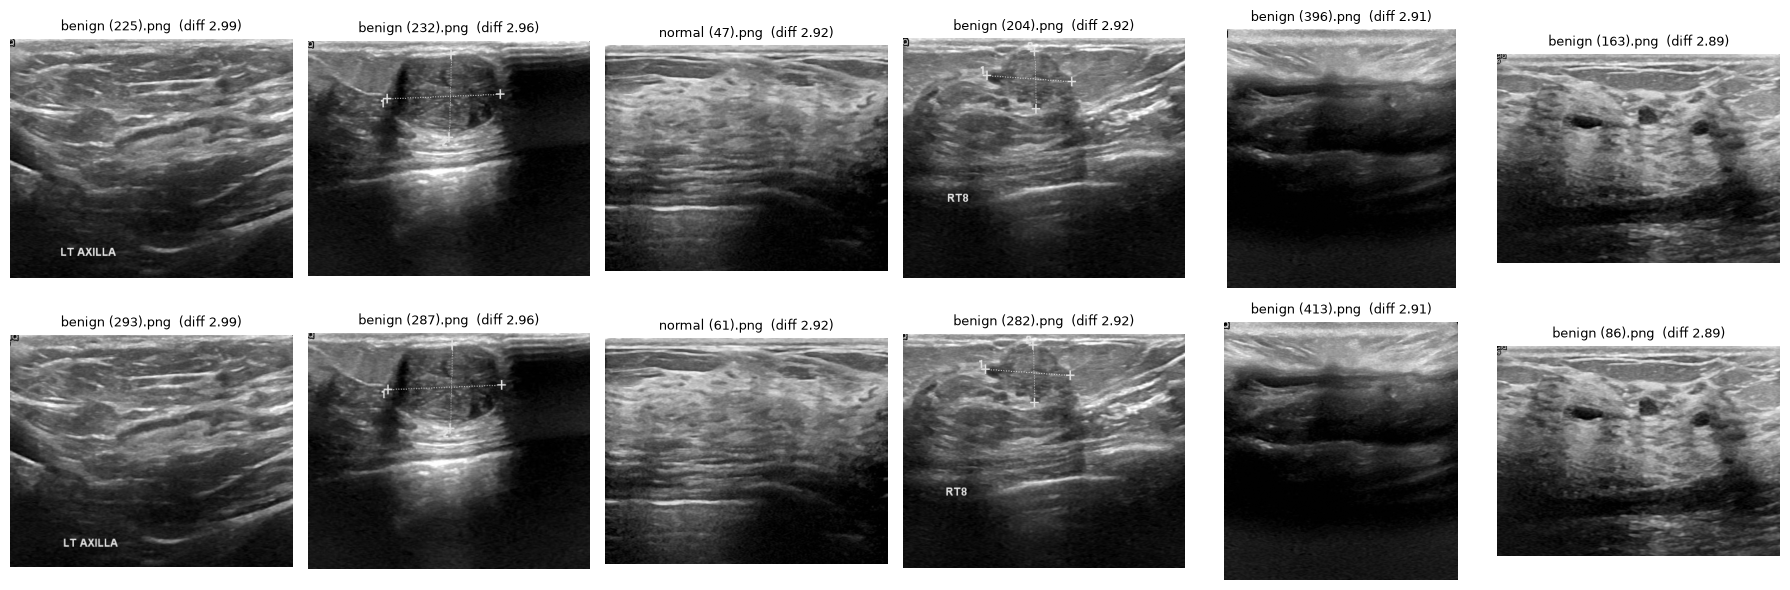

In [9]:
def show_pairs(pair_list, n=6):
    """Show duplicate pairs side by side: top row = first image, bottom row = its duplicate."""
    pair_list = pair_list[:n]
    fig, axes = plt.subplots(2, len(pair_list), figsize=(3 * len(pair_list), 6), squeeze=False)
    for col, (i, j, diff) in enumerate(pair_list):
        for row, k in enumerate([i, j]):
            path = df.loc[k, 'image_path']
            axes[row, col].imshow(load_gray(path), cmap='gray')
            axes[row, col].set_title(f'{Path(path).name}  (diff {diff})', fontsize=9)
            axes[row, col].axis('off')
    plt.tight_layout()
    plt.show()


show_pairs(sorted(pairs, key=lambda p: p[2], reverse=True))   # least similar first

## 5. Remove duplicates

- **Conflicting labels:** the same scan appears in two classes, so every copy is removed.
- **Same label:** the first copy is kept and the rest are removed.

Removed images are saved to `removed_images.csv` with the reason, so they can be reviewed later.

In [10]:
labels_per_group = df.groupby('duplicate_group')['label'].transform('nunique')   # how many classes per group

conflicting = df[labels_per_group > 1]                                           # same scan, different labels
extra_copies = df[(labels_per_group == 1) & df.duplicated('duplicate_group')]    # 2nd, 3rd ... copy

print(f'Conflicting labels: {len(conflicting)} images')
print(f'Extra copies:       {len(extra_copies)} images')
conflicting.sort_values('duplicate_group')[['image_path', 'label', 'duplicate_group']]

Conflicting labels: 11 images
Extra copies:       76 images


,image_path,label,duplicate_group
0,normal/normal (1).png,normal,0
321,benign/benign (269).png,benign,0
61,normal/normal (34).png,normal,61
508,benign/benign (437).png,benign,61
465,benign/benign (399).png,benign,465
773,malignant/malignant (93).png,malignant,465
169,benign/benign (131).png,benign,489
489,benign/benign (42).png,benign,489
727,malignant/malignant (51).png,malignant,489
504,benign/benign (433).png,benign,504


In [11]:
removed = pd.concat([
    conflicting.assign(reason='conflicting labels'),
    extra_copies.assign(reason='duplicate copy'),
])
removed.to_csv(DATA_DIR / 'removed_images.csv', index=False)

df = df.drop(removed.index).reset_index(drop=True)
print(f'{len(removed)} images removed, {len(df)} images left')
df['label'].value_counts()

87 images removed, 693 images left


label
benign       378
malignant    203
normal       112
Name: count, dtype: int64

## 6. Flag images with markers

Some scans have measurement calipers (`+`), dotted lines or text burned in. A model could learn "markers mean tumour" instead of looking at the tissue, so we flag these images to test on clean images later.

Markers are spotted two ways:
- **Thin bright strokes:** a *white top-hat* filter keeps small bright details (lines, text) and removes large bright areas (normal tissue).
- **Coloured pixels:** ultrasound is grey, so any clearly coloured pixel is an annotation.

This is a simple rule, not a perfect detector. Check the examples below.

In [12]:
def marker_pixels(path):
    """Count pixels that look like burned-in markers: thin bright strokes or coloured marks."""
    rgb = np.array(Image.open(DATA_DIR / path).convert('RGB')).astype(int)
    gray = rgb.mean(axis=2)

    thin_bright = (gray >= 240) & (white_tophat(gray, disk(3)) > 60)   # small, very bright details
    coloured = (rgb.max(axis=2) - rgb.min(axis=2)) > 30               # red/green/blue channels differ
    return int(thin_bright.sum() + coloured.sum())


df['marker_pixels'] = df['image_path'].apply(marker_pixels)
df['has_markers'] = df['marker_pixels'] > MARKER_PIXEL_THRESHOLD

pd.crosstab(df['label'], df['has_markers'])

has_markers,False,True
label,,
benign,144,234
malignant,80,123
normal,63,49


If markers are much more common in benign/malignant images than in normal ones, a model could cheat by spotting them. That's why we flag them.

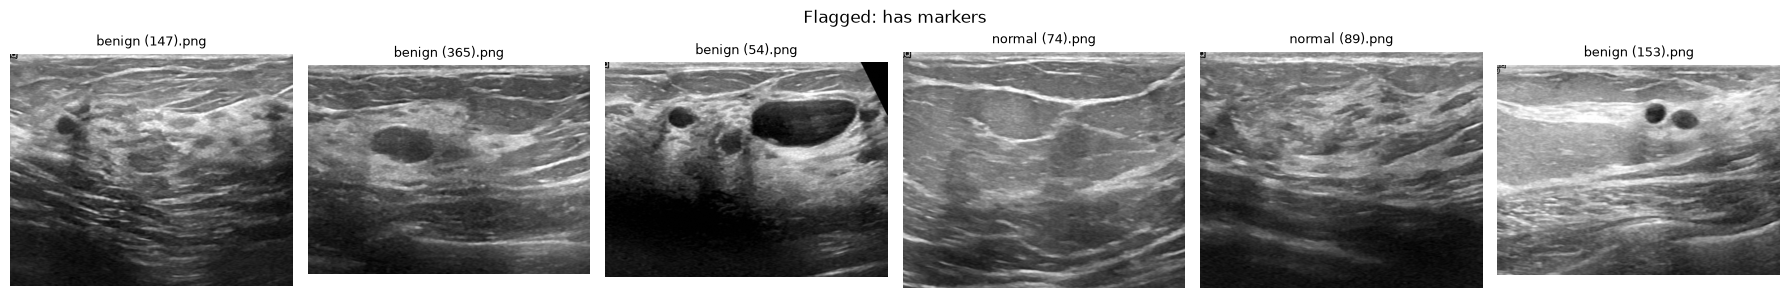

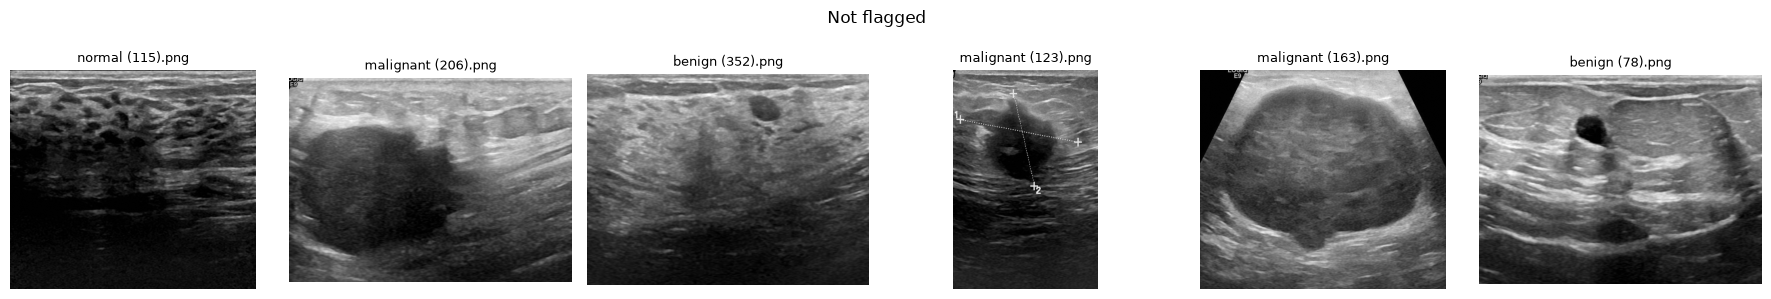

In [13]:
def show_images(paths, title):
    """Show a row of images with a title."""
    fig, axes = plt.subplots(1, len(paths), figsize=(3 * len(paths), 3), squeeze=False)
    for ax, path in zip(axes[0], paths):
        ax.imshow(load_gray(path), cmap='gray')
        ax.set_title(Path(path).name, fontsize=9)
        ax.axis('off')
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


flagged = df[df['has_markers']]
not_flagged = df[~df['has_markers']]
show_images(flagged.sample(min(6, len(flagged)), random_state=RANDOM_STATE)['image_path'], 'Flagged: has markers')
show_images(not_flagged.sample(min(6, len(not_flagged)), random_state=RANDOM_STATE)['image_path'], 'Not flagged')

## 7. Train / validation / test split

70% train, 15% validation, 15% test. `stratify` keeps the same normal / benign / malignant ratio in every split. Duplicates were already removed, so the same scan can't appear in two splits.

In [14]:
# First split off 30%, then cut that 30% in half: 15% validation, 15% test
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df['label'], random_state=RANDOM_STATE)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df['label'], random_state=RANDOM_STATE)

df['split'] = 'train'
df.loc[val_df.index, 'split'] = 'val'
df.loc[test_df.index, 'split'] = 'test'

pd.crosstab(df['label'], df['split'], margins=True)

split,test,train,val,All
label,,,,
benign,57,265,56,378
malignant,30,142,31,203
normal,17,78,17,112
All,104,485,104,693


## 8. Save the manifest

Every later notebook reads this file, so they all use the same images and the same split.

In [15]:
columns = ['image_path', 'mask_paths', 'label', 'width', 'height',
           'n_lesions', 'has_markers', 'duplicate_group', 'split']

df[columns].to_csv(DATA_DIR / 'manifest.csv', index=False)
print(f'Saved {len(df)} images to data/manifest.csv')
df[columns].head()

Saved 693 images to data/manifest.csv


,image_path,mask_paths,label,width,height,n_lesions,has_markers,duplicate_group,split
0,normal/normal (10).png,normal/normal (10)_mask.png,normal,501,485,0,False,1,train
1,normal/normal (100).png,normal/normal (100)_mask.png,normal,690,574,0,False,2,train
2,normal/normal (101).png,normal/normal (101)_mask.png,normal,678,572,0,False,3,train
3,normal/normal (102).png,normal/normal (102)_mask.png,normal,770,576,0,False,4,train
4,normal/normal (103).png,normal/normal (103)_mask.png,normal,772,574,0,False,5,test
